# 需求理解 Agent · 逐格运行记录（fork14 端到端）
Requirement-understanding agent · cell-by-cell run (fork14 end to end)

**本次运行的模型位置用的是"关键词规则替身"，不是 LLM**（还没有 API key）。替身之后的每一格都是真实代码、真实计算；只有关系表本身来自替身，所以第 ⑪ 节的分数**不是 Agent 的实验结果**。
把第 0 格的 `PROVIDER` 改成 `"anthropic"`、设置环境变量 `ANTHROPIC_API_KEY` 后重跑，就是真实结果。

**The model slot in this run is a keyword-rule stand-in, not an LLM** (no API key yet). Every cell after it is real code with real computation. Only the relation table comes from the stand-in, so the scores in section ⑪ are **not agent results**. Set `PROVIDER = "anthropic"` and `ANTHROPIC_API_KEY`, then re-run for real results.

| 格 / Cells | 节点 / Node | 读 / Reads | 写 / Writes |
|---|---|---|---|
| 1–3 | 数据 | `data/fork14_zones.json`, `data/fork14_brief.md` | — |
| 4 | 标准答案（只给评估） | `data/gold/fork14_gold.json` | — |
| 5–6 | ① 数值隔离 + 防泄题 | brief, 区域名称 | `state_1_prompt.json` |
| 7–8 | ② 关系 Agent | 提示词 | `state_2_table.json` |
| 9–10 | ⑤ 格式校验 | 模型回复 | （记录在 state_2） |
| 11 | ③ 置信度自检 | 低置信度的对 | `state_3_selfcheck.json` |
| 12 | ⑥ 编译 | 关系表 + 面积表 | `instance_agent.json` |
| 13–16 | ⑦ 求解 + ⑨ 几何检查 | 算例 JSON | `layout_*.json`, 布局图 |
| 17–19 | ⑪ 评估 | 关系表 + gold | `metrics.json` |
| 20 | pump14（只测关系） | | |
| 21 | 本次运行写出的文件 | | `meta.json` |

In [1]:
# 0 · 设置 / Setup
import json, os, sys, time, re, copy
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK SC", "PingFang SC", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
from IPython.display import display

ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
from agent.llm import LLM
from agent import relation_agent as ra
from agent.validate import validate_table
from agent.compile import compile_instance, weight_matrix
from agent import solver_bridge as sb

PROVIDER = "keyword"          # 真实运行改成 "anthropic" / real run: "anthropic"
MODEL    = "keyword-rule"     # 例如 / e.g. "claude-sonnet-5-5"
SOLVER_DIR = os.environ.get("SOLVER_DIR", "/home/claude/solver_v2")   # 实验一求解器（work_v2, 10-11 版）
CASE = "fork14"
SEED, TIME_LIMIT = 0, 30      # 求解器种子、时限（秒）

# 假设待定（README 第 1–3 条）/ pending assumptions
FLOOR = {"W": 310, "H": 285}              # 厂区 310 × 285 m，填充率 75.2%（三个候选之一）
SHAPE = {"type": "Rmax", "value": 5}      # 长宽比 ≤ 5（书中最大的是办公楼 300/60 = 5）
X_MIN_DIST = None                         # X 最小净距 D：未定；本求解器也不支持此约束

RUN_DIR = os.path.join(ROOT, "runs_notebook", time.strftime("%Y%m%d-%H%M%S") + f"_{CASE}_{PROVIDER}")
os.makedirs(RUN_DIR, exist_ok=True)
def save(name, obj):
    with open(os.path.join(RUN_DIR, name), "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=1)
print("ROOT      ", ROOT)
print("RUN_DIR   ", os.path.relpath(RUN_DIR, ROOT))
print("PROVIDER  ", PROVIDER, "| MODEL", MODEL)
print("SOLVER_DIR", SOLVER_DIR, "| exists:", os.path.isdir(SOLVER_DIR))

ROOT       /home/claude/09_agent
RUN_DIR    runs_notebook/20261025-035723_fork14_keyword
PROVIDER   keyword | MODEL keyword-rule
SOLVER_DIR /home/claude/solver_v2 | exists: True


## 1 · 数据 / Data
面积表：只进编译 ⑥，不进提示词。  Zone table: goes to compile ⑥ only, never into the prompt.

In [2]:
# 1 · 面积表 / zone table
zt = json.load(open(os.path.join(ROOT, "data", f"{CASE}_zones.json"), encoding="utf-8"))
zones_df = pd.DataFrame(zt["zones"]).set_index("id")
display(zones_df)
print("面积合计 / total area =", zones_df["area"].sum(), "m²   (书中给 66,464)")
print("厂区面积 / floor area =", FLOOR["W"] * FLOOR["H"], "m²   填充率 / fill =",
      f'{zones_df["area"].sum() / (FLOOR["W"] * FLOOR["H"]):.1%}')

,name,length,width,area
id,,,,
1,原材料库,72,36,2592
2,油料库,36,36,1296
3,标准件外购件库,48,36,1728
4,机加工车间,72,36,2592
5,热处理车间,90,30,2700
6,焊接车间,90,30,2700
7,变速器车间,72,36,2592
8,总装车间,180,96,17280
9,工具车间,60,24,1440


面积合计 / total area = 66464 m²   (书中给 66,464)
厂区面积 / floor area = 88350 m²   填充率 / fill = 75.2%


In [3]:
# 2 · Agent 能读到的东西 / what the agent may read
brief, zones = ra.load_inputs(CASE)      # 只取编号+名称，面积留在 zones_df
print("zones =", zones)
print("brief:", len(brief), "字 /", brief.count(chr(10)) + 1, "行")

zones = {1: '原材料库', 2: '油料库', 3: '标准件外购件库', 4: '机加工车间', 5: '热处理车间', 6: '焊接车间', 7: '变速器车间', 8: '总装车间', 9: '工具车间', 10: '油漆车间', 11: '试车车间', 12: '成品库', 13: '办公服务楼', 14: '车库'}
brief: 877 字 / 40 行


In [4]:
# 3 · brief 原文（你审核的就是这份） / the brief text under review
print(brief)

# 工厂说明：电瓶叉车总装厂

## 1. 产品
本厂生产电瓶叉车（蓄电池驱动的叉车）。厂区内有 14 个作业单位，部分零件自制，部分标准件和零部件外购，变速器自制，最后在厂内总装、涂装、试车后入库。

## 2. 作业单位及功能
| 编号 | 作业单位 | 功能 |
|---|---|---|
| 1 | 原材料库 | 存放生产用原材料 |
| 2 | 油料库 | 存放燃油、润滑油等油料 |
| 3 | 标准件外购件库 | 存放标准件和外购零部件 |
| 4 | 机加工车间 | 零件的切削加工 |
| 5 | 热处理车间 | 零件的热处理 |
| 6 | 焊接车间 | 结构件的焊接 |
| 7 | 变速器车间 | 变速器的加工与装配 |
| 8 | 总装车间 | 叉车整车装配 |
| 9 | 工具车间 | 制造和修理生产用工具、工装 |
| 10 | 油漆车间 | 涂装 |
| 11 | 试车车间 | 整车试验 |
| 12 | 成品库 | 存放合格的叉车 |
| 13 | 办公服务楼 | 行政管理、技术部门和职工生活服务 |
| 14 | 车库 | 停放厂内运输车辆 |

## 3. 工艺流程（物料走向）
1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原材料。
2. 机加工车间加工出的零件，一部分送热处理车间，一部分送变速器车间，一部分直接送总装车间。
3. 热处理车间与工具车间之间有工件往来。
4. 焊接车间焊好的焊接件送油漆车间涂装。
5. 标准件外购件库向变速器车间和总装车间供应标准件和外购件。
6. 变速器车间装好的变速器送总装车间。
7. 工具车间与总装车间之间有工具往来。
8. 总装车间与油漆车间之间有工件往来（涂装）。
9. 总装好的叉车送试车车间试车，试车后送成品库。
10. 油料库向油漆车间和试车车间供应油料。

## 4. 书外常识补充（审核时可整节删除）
- 油料库存放的油料、油漆车间使用的油漆和溶剂属于易燃物。
- 热处理车间有高温炉和烟气。
- 焊接车间有焊接火花、烟尘和弧光。



### 标准答案（只给评估脚本用） / Answer key (evaluation only)
这一格读 `data/gold/`。Agent 代码 `agent/*.py` 不读它（有测试检查）。
This cell reads `data/gold/`. Agent code never does (a test checks this).

In [5]:
# 4 · gold 14×14 + 行合计核对 / gold matrix + row-sum check
from eval.gold import load_gold, full_matrix, row_sums, SCORE
gold = load_gold(CASE)
G = pd.DataFrame(full_matrix(gold["pairs"], 14), index=range(1, 15), columns=range(1, 15))
G["合计"] = row_sums(gold["pairs"], 14)
G["书中"] = gold["expected_row_sums"]
display(G)
print("行合计全部一致 / all row sums match:", (G["合计"] == G["书中"]).all())
print("等级分布 / grade counts:", pd.Series(list(gold["pairs"].values())).value_counts().reindex(list("AEIOUX")).to_dict())

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,合计,书中
1,-,I,I,E,E,E,U,U,I,U,U,U,U,I,17,17
2,I,-,I,U,X,X,U,U,U,E,O,U,X,I,7,7
3,I,I,-,U,U,U,I,E,U,U,U,U,U,I,11,11
4,E,U,U,-,A,O,E,I,I,U,O,U,I,U,18,18
5,E,X,U,A,-,U,U,U,E,X,U,U,X,U,7,7
6,E,X,U,O,U,-,U,U,U,U,U,U,X,O,3,3
7,U,U,I,E,U,U,-,E,U,U,I,U,I,O,13,13
8,U,U,E,I,U,U,E,-,I,E,A,U,I,I,21,21
9,I,U,U,I,E,U,U,I,-,U,U,U,O,U,10,10
10,U,E,U,U,X,U,U,E,U,-,U,U,X,U,4,4


行合计全部一致 / all row sums match: True
等级分布 / grade counts: {'A': 3, 'E': 9, 'I': 18, 'O': 8, 'U': 46, 'X': 7}


## ① 数值隔离 + 防泄题 / Number isolation + leak checks
来源 OptiMUS：数值不进提示词。下面打印的就是发给模型的全部内容。
Source OptiMUS: numbers stay out of the prompt. Below is everything the model receives.

In [6]:
# 5 · 实际发出的提示词 / the actual prompt
system = ra.SYSTEM_TABLE
user = ra.table_prompt(brief, zones)
save("state_1_prompt.json", {"system": system, "user": user})
print("=== SYSTEM (", len(system), "字) ===")
print(system)
print()
print("=== USER 末尾 / end of user message ===")
print(user[user.index("# 作业单位清单"):])

=== SYSTEM ( 533 字) ===
你是工厂布置中的作业单位相互关系分析员。你只做一件事：根据工厂说明，判断每一对作业单位之间的接近程度等级，并用一句话写出理由。不需要考虑面积、坐标或距离。

等级定义（SLP 系统布置设计，Muther）：
A：绝对必要靠近
E：特别重要靠近
I：重要
O：一般
U：不重要（两者之间没有需要考虑的关系）
X：不希望靠近

常见判断依据（可同时考虑多条）：
1. 物料流动：工艺上前后衔接、物料搬运往来
2. 共用设备、场地或人员
3. 管理与服务联系：监督管理、辅助服务、人员往来
4. 安全、污染、噪声、振动：需要隔开时判 X
大多数单位对之间没有明显关系，判 U 是正常的。

输出要求：
- 只输出一个 ```json 代码块，格式为 {"pairs": [{"i": 1, "name_i": "...", "j": 2, "name_j": "...", "grade": "U", "reason": "一句话理由", "confidence": 4}, ...]}
- 每一对单位都要给出，只列 i<j，先按 i 再按 j 排序。
- reason：一句中文，说明依据。
- confidence：1–5 的整数，5 表示很确定，1 表示几乎是猜的。

=== USER 末尾 / end of user message ===
# 作业单位清单（共 14 个）
- [1] 原材料库
- [2] 油料库
- [3] 标准件外购件库
- [4] 机加工车间
- [5] 热处理车间
- [6] 焊接车间
- [7] 变速器车间
- [8] 总装车间
- [9] 工具车间
- [10] 油漆车间
- [11] 试车车间
- [12] 成品库
- [13] 办公服务楼
- [14] 车库

请给出全部 91 对的等级。


In [7]:
# 6 · 防泄题自动检查 / automatic leak checks
checks = {
  "没有小数（物流强度）":        not re.search(r"\d+\.\d+", user),
  "没有尺寸（如 72×36）":        not re.search(r"\d+\s*[×x]\s*\d+", user),
  "没有面积数":                  not any(str(a) in user for a in zones_df["area"]),
  "brief 里没有单独的等级字母":   not re.search(r"(?<![A-Za-z])[AEIOUX](?![A-Za-z])", brief),
  "没有 gold 里的'行 i: jG'写法": not re.search(r"\b\d{1,2}[AEIOUX]\b", user),
}
display(pd.DataFrame({"检查 / check": checks.keys(), "通过 / pass": checks.values()}))
assert all(checks.values())

,检查 / check,通过 / pass
0,没有小数（物流强度）,True
1,没有尺寸（如 72×36）,True
2,没有面积数,True
3,brief 里没有单独的等级字母,True
4,没有 gold 里的'行 i: jG'写法,True


## ② 关系整理 Agent / Relation agent
来源：SLP 等级（Muther）；每对一行（Holodeck）；一个 Agent 只做一件事（Co-Layout）。
本次 `PROVIDER = "keyword"`：规则是"brief 第 3 节同一行同时提到两个单位 → E（行里只说'往来'时置信度 3，否则 4）；其他 → U"。
This run's stand-in rule: two units named in the same line of section 3 → E (confidence 3 if the line only says "exchanges", else 4); otherwise U.

In [8]:
# 7 · 调用模型 + ⑤ 校验循环 / call the model with the ⑤ validation loop
llm = LLM({"provider": PROVIDER, "model": MODEL, "temperature": None, "max_tokens": 16000})
t = ra.ask_table(llm, brief, zones, max_retries=2, save=lambda r: save("state_2_table.json", r))
print("尝试次数 / attempts:", len(t["attempts"]), "| failed:", t["failed"])
print("token / time:", llm.totals())
reply = t["attempts"][-1]["reply"]
print("\n回复前 6 行 / first 6 lines of the reply:")
print("\n".join(reply.splitlines()[:6]))

尝试次数 / attempts: 1 | failed: False
token / time: {'n_calls': 1, 'input_tokens': 0, 'output_tokens': 0, 'seconds': 0.001}

回复前 6 行 / first 6 lines of the reply:
```json
{
"pairs": [
{
"i": 1,
"name_i": "原材料库",


In [9]:
# 8 · 91 对整理成表 / the 91 pairs as a table
pairs = t["pairs"]
P = pd.DataFrame([{"pair": k, "i": int(k.split("-")[0]), "j": int(k.split("-")[1]),
                   "单位 i": zones[int(k.split("-")[0])], "单位 j": zones[int(k.split("-")[1])], **v}
                  for k, v in pairs.items()])
print("共", len(P), "对；等级分布:", P["grade"].value_counts().reindex(list("AEIOUX"), fill_value=0).to_dict())
display(P[P["grade"] != "U"][["pair", "单位 i", "单位 j", "grade", "confidence", "reason"]])

共 91 对；等级分布: {'A': 0, 'E': 24, 'I': 0, 'O': 0, 'U': 67, 'X': 0}


,pair,单位 i,单位 j,grade,confidence,reason
2,1-4,原材料库,机加工车间,E,4,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
3,1-5,原材料库,热处理车间,E,4,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
4,1-6,原材料库,焊接车间,E,4,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
7,1-9,原材料库,工具车间,E,4,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
20,2-10,油料库,油漆车间,E,4,关键词规则：同一行提到两者「10. 油料库向油漆车间和试车车间供应油料。」
21,2-11,油料库,试车车间,E,4,关键词规则：同一行提到两者「10. 油料库向油漆车间和试车车间供应油料。」
28,3-7,标准件外购件库,变速器车间,E,4,关键词规则：同一行提到两者「5. 标准件外购件库向变速器车间和总装车间供应标准件和外购件。」
29,3-8,标准件外购件库,总装车间,E,4,关键词规则：同一行提到两者「5. 标准件外购件库向变速器车间和总装车间供应标准件和外购件。」
36,4-5,机加工车间,热处理车间,E,4,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
37,4-6,机加工车间,焊接车间,E,4,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...


## ⑤ 格式校验 / Format validation
先看真实回复的校验结果，再人为制造 4 种错误，看校验器抓到什么、回传给模型的原话是什么。
First the real reply, then 4 planted errors: what the validator catches, and the exact message sent back.

In [10]:
# 9 · 真实回复的校验结果 / validation of the real reply
_, errs, corr = validate_table(reply, zones)
print("errors:", errs)
print("corrections:", corr)

errors: []
corrections: []


In [11]:
# 10 · 人为制造 4 种错误 / plant 4 errors
d = json.loads(re.search(r"```json\s*(\{.*\})\s*```", reply, re.S).group(1))
rows = d["pairs"]
rows = [r for r in rows if (r["i"], r["j"]) != (2, 3)]                      # (a) 删掉 2-3
for r in rows:
    if (r["i"], r["j"]) == (1, 2): r["name_j"] = "油料仓库"                  # (b) 名称写错一个字
    if (r["i"], r["j"]) == (4, 5): r["grade"] = "B"                         # (c) 非法等级
rows.append(dict(next(r for r in rows if (r["i"], r["j"]) == (1, 4))))     # (d) 重复 1-4
bad = "```json\n" + json.dumps({"pairs": rows}, ensure_ascii=False) + "\n```"
_, errs, corr = validate_table(bad, zones)
print("纠正（不算错）/ auto-corrected:", corr)
print("\n回传给模型的原话 / message sent back to the model:\n")
print(ra.feedback_message(errs))

纠正（不算错）/ auto-corrected: [{'row': 1, 'given': '油料仓库', 'to': '油料库', 'id': 2, 'edit_distance': 1}]

回传给模型的原话 / message sent back to the model:

你的输出没有通过格式检查，问题如下：
- 4-5: 等级「B」不合法，只能是 A/E/I/O/U/X
- 1-4: 重复出现
- 缺少 2 对: 2-3, 4-5
请输出完整的修正后的 JSON（全部单位对）。


## ③ 置信度自检 / Confidence self-check
来源 OptiMUS。confidence ≤ 3 的对，单独再问一次（只给这一对 + brief）。
Source OptiMUS. Pairs with confidence ≤ 3 are asked again, one at a time.

In [12]:
# 11 · 自检 / self-check
low = P[P["confidence"] <= 3][["pair", "单位 i", "单位 j", "grade", "confidence", "reason"]]
print("需要复核的对 / pairs to re-check:", len(low))
display(low)
if len(low):
    k = low.iloc[0]["pair"]; i, j = map(int, k.split("-"))
    print("第一对的复核提示词（末尾）/ re-check prompt for the first pair (end):\n")
    q = ra.recheck_prompt(brief, zones, i, j, pairs[k]); print(q[q.index("# 需要复核的一对"):])
sc = ra.self_check(llm, brief, zones, pairs, threshold=3, workers=4, save=lambda r: save("state_3_selfcheck.json", r))
print("\n复核", sc["n_low"], "对，改了", sc["n_changed"], "对")
display(pd.DataFrame([{"pair": x["pair"], "前 / before": x["before"]["grade"],
                       "后 / after": x["after"]["grade"] if x["after"] else None, "改了": x["changed"]} for x in sc["log"]]))
final_pairs = sc["pairs"]

需要复核的对 / pairs to re-check: 2


,pair,单位 i,单位 j,grade,confidence,reason
70,8-9,总装车间,工具车间,E,3,关键词规则：同一行提到两者「7. 工具车间与总装车间之间有工具往来。」
71,8-10,总装车间,油漆车间,E,3,关键词规则：同一行提到两者「8. 总装车间与油漆车间之间有工件往来（涂装）。」


第一对的复核提示词（末尾）/ re-check prompt for the first pair (end):

# 需要复核的一对
PAIR [8] 总装车间 与 [9] 工具车间

你之前的判断：等级 E，理由「关键词规则：同一行提到两者「7. 工具车间与总装车间之间有工具往来。」」，置信度 3。
请独立重新判断这一对，确认或修改。

复核 2 对，改了 0 对


,pair,前 / before,后 / after,改了
0,8-9,E,E,False
1,8-10,E,E,False


## ⑥ 编译 / Compile
A=4 E=3 I=2 O=1 U=0 → 权重矩阵；X → `min_separation` 列表（不进权重）。面积直接取面积表。
Grades → weight matrix; X → a `min_separation` list (not a weight). Areas come straight from the zone table.

In [13]:
# 12 · 编译成求解器算例 / compile into a solver instance
inst_agent = compile_instance("fork14_agent", os.path.join(ROOT, "data", "fork14_zones.json"), final_pairs,
                              FLOOR, SHAPE, X_MIN_DIST, f"{PROVIDER}:{MODEL}")
save("instance_agent.json", inst_agent)
W = pd.DataFrame(weight_matrix(final_pairs, 14), index=range(1, 15), columns=range(1, 15))
print("对称 / symmetric:", (W.values == W.values.T).all(), "| 非零权重对数:", len(inst_agent["weights"]))
display(W)
print("weights 前 6 条:", inst_agent["weights"][:6])
print("min_separation:", inst_agent["min_separation"])
print("areas:", inst_agent["areas"])

对称 / symmetric: True | 非零权重对数: 24


,1,2,3,4,5,6,7,8,9,10,11,12,13,14
1,0,0,0,3,3,3,0,0,3,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,3,3,0,0,0
3,0,0,0,0,0,0,3,3,0,0,0,0,0,0
4,3,0,0,0,3,3,3,3,3,0,0,0,0,0
5,3,0,0,3,0,3,3,3,3,0,0,0,0,0
6,3,0,0,3,3,0,0,0,3,3,0,0,0,0
7,0,0,3,3,3,0,0,3,0,0,0,0,0,0
8,0,0,3,3,3,0,3,0,3,3,0,0,0,0
9,3,0,0,3,3,3,0,3,0,0,0,0,0,0
10,0,3,0,0,0,3,0,3,0,0,3,0,0,0


weights 前 6 条: [[1, 4, 3], [1, 5, 3], [1, 6, 3], [1, 9, 3], [2, 10, 3], [2, 11, 3]]
min_separation: []
areas: [2592.0, 1296.0, 1728.0, 2592.0, 2700.0, 2700.0, 2592.0, 17280.0, 1440.0, 1440.0, 2304.0, 5000.0, 18000.0, 4800.0]


## ⑦ 求解 + ⑨ 几何检查 / Solve + geometry check
求解器 = 实验一的"ours"（两阶段 SA + SOCP），代码来自 `~/FLP/results/bench_work/work_v2.tgz`（10-11 版），**一行未改**。
**这个求解器没有最小间距约束**，所以 X 对现在不受约束，只在事后量实际间距。
Solver = Experiment 1 "ours", unmodified (10-11 version). **It has no minimum-distance constraint**, so X pairs are not enforced; we only measure their gaps afterwards.

打分规则：两个布局都用 **gold 权重**算目标值。  Scoring: both layouts use **gold weights**.

求解器按时间预算停止，所以同一个种子重跑，目标值也可能略有不同；正式实验要多跑几个种子。
The solver stops on a time budget, so the same seed can give slightly different values on a re-run; the real experiment should use several seeds.

In [14]:
# 13 · 用 Agent 的关系表求解 / solve with the agent's table
res_agent = sb.solve(inst_agent, SOLVER_DIR, seed=SEED, time_limit=TIME_LIMIT, log=lambda *a: None)
save("layout_agent.json", res_agent)
print("可行 / feasible:", res_agent["feasible"], "| 违规 / violations:", res_agent["violations"], "| 用时", res_agent["wall"], "s")

可行 / feasible: True | 违规 / violations: [] | 用时 30.0 s


In [15]:
# 14 · 参考上限：用 gold 关系表求解 / reference: solve with the gold table
gold_pairs = {f"{i}-{j}": {"grade": g} for (i, j), g in gold["pairs"].items()}
inst_gold = compile_instance("fork14_gold", os.path.join(ROOT, "data", "fork14_zones.json"), gold_pairs,
                             FLOOR, SHAPE, X_MIN_DIST, "gold")
res_gold = sb.solve(inst_gold, SOLVER_DIR, seed=SEED, time_limit=TIME_LIMIT, log=lambda *a: None)
save("layout_gold.json", res_gold)
print("可行 / feasible:", res_gold["feasible"], "| 违规 / violations:", res_gold["violations"], "| 用时", res_gold["wall"], "s")

可行 / feasible: True | 违规 / violations: [] | 用时 30.0 s


In [16]:
# 15 · 用 gold 权重打分 + X 对实际间距 / score with gold weights + X-pair gaps
Wg = np.array(weight_matrix(gold_pairs, 14))
x_pairs = [tuple(map(int, k.split("-"))) for k, v in gold_pairs.items() if v["grade"] == "X"]
score = pd.DataFrame({
  "关系表来源": [f"{PROVIDER}", "gold（上限参考）"],
  "可行": [res_agent["feasible"], res_gold["feasible"]],
  "gold 权重目标值": [round(sb.cost_with(Wg, res_agent["rects"]), 1), round(sb.cost_with(Wg, res_gold["rects"]), 1)],
})
score["比 gold 差"] = (score["gold 权重目标值"] / score["gold 权重目标值"].iloc[1] - 1).map("{:+.1%}".format)
display(score)
gx = pd.DataFrame(sb.x_gaps(res_agent["rects"], x_pairs)).rename(columns={"gap": f"间距（{PROVIDER}）"})
gx[ "间距（gold）"] = [g["gap"] for g in sb.x_gaps(res_gold["rects"], x_pairs)]
gx["单位"] = [f'{zones[i]} – {zones[j]}' for i, j in x_pairs]
display(gx[["pair", "单位", f"间距（{PROVIDER}）", "间距（gold）"]])
print("间距 ≤ 0 表示两块贴在一起 / gap ≤ 0 means touching")

,关系表来源,可行,gold 权重目标值,比 gold 差
0,keyword,True,9116.2,+31.6%
1,gold（上限参考）,True,6929.3,+0.0%


,pair,单位,间距（keyword）,间距（gold）
0,2-5,油料库 – 热处理车间,102.72,66.00
1,2-6,油料库 – 焊接车间,16.97,89.24
2,2-13,油料库 – 办公服务楼,17.85,104.25
3,5-10,热处理车间 – 油漆车间,85.75,65.32
4,5-13,热处理车间 – 办公服务楼,0.00,4.16
5,6-13,焊接车间 – 办公服务楼,0.00,4.16
6,10-13,油漆车间 – 办公服务楼,15.67,185.67


间距 ≤ 0 表示两块贴在一起 / gap ≤ 0 means touching


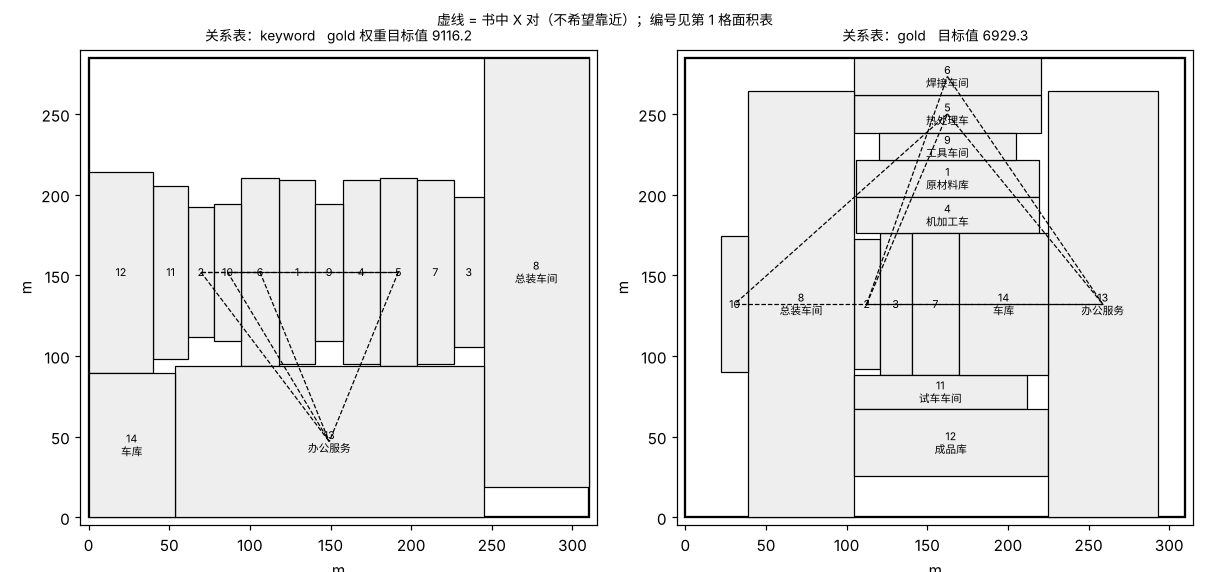

In [17]:
# 16 · 布局图 / layout plots
def plot(ax, rects, title):
    ax.add_patch(Rectangle((0, 0), FLOOR["W"], FLOOR["H"], fill=False, lw=1.5, ec="black"))
    for k, (x, y, w, h) in enumerate(rects, 1):
        ax.add_patch(Rectangle((x, y), w, h, fc="#eeeeee", ec="black", lw=0.8))
        lab = f"{k}\n{zones[k][:4]}" if w >= 45 else f"{k}"   # 窄条只标编号 / narrow: number only
        ax.text(x + w / 2, y + h / 2, lab, ha="center", va="center", fontsize=7)
    for i, j in x_pairs:
        a, b = rects[i - 1], rects[j - 1]
        ax.plot([a[0] + a[2] / 2, b[0] + b[2] / 2], [a[1] + a[3] / 2, b[1] + b[3] / 2], "k--", lw=0.8)
    ax.set_xlim(-5, FLOOR["W"] + 5); ax.set_ylim(-5, FLOOR["H"] + 5); ax.set_aspect("equal")
    ax.set_title(title, fontsize=9); ax.set_xlabel("m"); ax.set_ylabel("m")
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2), dpi=110)
plot(axs[0], res_agent["rects"], f"关系表：{PROVIDER}   gold 权重目标值 {score.iloc[0, 2]}")
plot(axs[1], res_gold["rects"], f"关系表：gold   目标值 {score.iloc[1, 2]}")
fig.suptitle("虚线 = 书中 X 对（不希望靠近）；编号见第 1 格面积表", fontsize=9); fig.tight_layout()
fig.savefig(os.path.join(RUN_DIR, "layouts.png")); plt.close(fig)
from IPython.display import Image
display(Image(filename=os.path.join(RUN_DIR, "layouts.png")))

## ⑪ 评估 / Evaluation
逐对和 gold 比。再提醒一次：本次关系表来自关键词替身，下面的分数是**替身的分数**。
Pair-by-pair against gold. Again: these are **the stand-in's scores**, not the agent's.

In [18]:
# 17 · 指标 / metrics
from eval.eval_relations import evaluate
KEYS = ["exact", "within1", "kappa_linear", "kappa_unweighted", "nonU_recall", "nonU_precision", "X_recall"]
m_run = evaluate(gold["pairs"], final_pairs, gold["exclude"])
m_allU = evaluate(gold["pairs"], {k: "U" for k in gold["pairs"]}, gold["exclude"])
M_ = pd.DataFrame([{k: m_allU[k] for k in KEYS}, {k: m_run[k] for k in KEYS}], index=["全 U 基线", f"{PROVIDER}（自检后）"]).round(3)
display(M_)
save("metrics.json", {k: v for k, v in m_run.items() if k != "errors"})

,exact,within1,kappa_linear,kappa_unweighted,nonU_recall,nonU_precision,X_recall
全 U 基线,0.505,0.593,0.000,0.000,0.0,NaN,0.0
keyword（自检后）,0.538,0.681,0.399,0.233,0.4,0.75,0.0


In [19]:
# 18 · 混淆矩阵 / confusion matrix (rows = gold, cols = predicted)
cm = pd.DataFrame(m_run["confusion"], index=[f"gold {g}" for g in "AEIOUX"], columns=[f"预测 {g}" for g in "AEIOUX"])
display(cm)
print("对角线 = 判对的对数 / diagonal = correct pairs:", int(np.trace(cm.values)), "/", m_run["n_pairs"])

,预测 A,预测 E,预测 I,预测 O,预测 U,预测 X
gold A,0,2,0,0,1,0
gold E,0,9,0,0,0,0
gold I,0,5,0,0,13,0
gold O,0,2,0,0,6,0
gold U,0,6,0,0,40,0
gold X,0,0,0,0,7,0


对角线 = 判对的对数 / diagonal = correct pairs: 49 / 91


In [20]:
# 19 · 错误分类 + 例子 / error types with examples
display(pd.DataFrame([m_run["error_counts"]]).reindex(columns=["等级偏高", "等级偏低", "漏判X", "误判X", "有关系判成U", "U判成有关系"], fill_value=0))
ex = [{"类别": t, "pair": e["pair"], "单位": " – ".join(zones[int(x)] for x in e["pair"].split("-")),
       "gold": e["gold"], "预测": e["pred"], "理由": e["reason"]}
      for t, es in m_run["errors"].items() for e in es[:2]]
display(pd.DataFrame(ex))

,等级偏高,等级偏低,漏判X,误判X,有关系判成U,U判成有关系
0,7,2,7,0,20,6


,类别,pair,单位,gold,预测,理由
0,有关系判成U,1-2,原材料库 – 油料库,I,U,关键词规则：没有一行同时提到两者
1,有关系判成U,1-3,原材料库 – 标准件外购件库,I,U,关键词规则：没有一行同时提到两者
2,等级偏高,1-9,原材料库 – 工具车间,I,E,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
3,等级偏高,2-11,油料库 – 试车车间,O,E,关键词规则：同一行提到两者「10. 油料库向油漆车间和试车车间供应油料。」
4,漏判X,2-5,油料库 – 热处理车间,X,U,关键词规则：没有一行同时提到两者
5,漏判X,2-6,油料库 – 焊接车间,X,U,关键词规则：没有一行同时提到两者
6,等级偏低,4-5,机加工车间 – 热处理车间,A,E,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
7,等级偏低,11-12,试车车间 – 成品库,A,E,关键词规则：同一行提到两者「9. 总装好的叉车送试车车间试车，试车后送成品库。」
8,U判成有关系,5-6,热处理车间 – 焊接车间,U,E,关键词规则：同一行提到两者「1. 原材料库向机加工车间、热处理车间、焊接车间和工具车间供应原...
9,U判成有关系,5-7,热处理车间 – 变速器车间,U,E,关键词规则：同一行提到两者「2. 机加工车间加工出的零件，一部分送热处理车间，一部分送变速器...


## pump14（只测关系，没有面积） / pump14 (relations only)
同一套代码换算例。4–6 排除，按 90 对算。  Same code, other case; pair 4–6 excluded.

In [21]:
# 20 · pump14
b2, z2 = ra.load_inputs("pump14")
t2 = ra.ask_table(LLM({"provider": PROVIDER, "model": MODEL}), b2, z2)
sc2 = ra.self_check(LLM({"provider": PROVIDER, "model": MODEL}), b2, z2, t2["pairs"])
g2 = load_gold("pump14")
r2 = evaluate(g2["pairs"], sc2["pairs"], g2["exclude"]); a2 = evaluate(g2["pairs"], {k: "U" for k in g2["pairs"]}, g2["exclude"])
display(pd.DataFrame([{k: a2[k] for k in KEYS}, {k: r2[k] for k in KEYS}], index=["全 U 基线", f"{PROVIDER}（自检后）"]).round(3))

,exact,within1,kappa_linear,kappa_unweighted,nonU_recall,nonU_precision,X_recall
全 U 基线,0.733,0.811,0.000,0.000,0.000,NaN,0.0
keyword（自检后）,0.756,0.889,0.489,0.262,0.333,0.889,0.0


In [22]:
# 21 · 本次运行写出的文件 / files written by this run
save("meta.json", {"provider": PROVIDER, "model": MODEL, "case": CASE, "seed": SEED, "time_limit": TIME_LIMIT,
                   "floor": FLOOR, "shape": SHAPE, "x_min_dist": X_MIN_DIST, "solver_dir": SOLVER_DIR,
                   "llm_totals": llm.totals(), "date": time.strftime("%Y-%m-%d %H:%M:%S")})
for f in sorted(os.listdir(RUN_DIR)):
    print(f"{os.path.getsize(os.path.join(RUN_DIR, f)):>8,d} B  {f}")

   1,260 B  instance_agent.json
   1,530 B  layout_agent.json
   1,512 B  layout_gold.json
  85,946 B  layouts.png
     381 B  meta.json
     661 B  metrics.json
   3,722 B  state_1_prompt.json
  36,804 B  state_2_table.json
  13,841 B  state_3_selfcheck.json
